# 02 — Exploratory Data Analysis (Real Doppler RAD-DAR)

**Input:** `../data/processed/raddar.npz` (output of `01_data_loading.ipynb`)
**Output:** figures in `../figures/` for the EDA section of the PRDL and MLLB reports.

Questions:
1. How are the classes and sessions distributed across the train / validation / test sets?
2. What does a typical map of each class look like (mean and variability)?
3. How do the classes differ in Doppler (velocity) and range?
4. Which simple physical features separate the classes?
5. Are there artefacts that a network could use as a shortcut?
6. How different are the sessions (recordings) from each other?
7. Do the classes separate in a 2D projection (PCA)?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

SEED = 42
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

d = np.load("../data/processed/raddar.npz", allow_pickle=True)
X, y = d["X"], d["y"]
class_names = [str(c) for c in d["class_names"]]
sessions = d["sessions"]
split = np.empty(len(y), dtype=object)
split[d["train_idx"]], split[d["val_idx"]], split[d["test_idx"]] = "train", "val", "test"
PAL = {"Cars": "#457b9d", "Drones": "#e76f51", "People": "#2a9d8f"}
cls = np.array(class_names)[y]
print(X.shape, class_names)

(17485, 11, 61) ['Cars', 'Drones', 'People']


## 1. Classes, sessions and splits

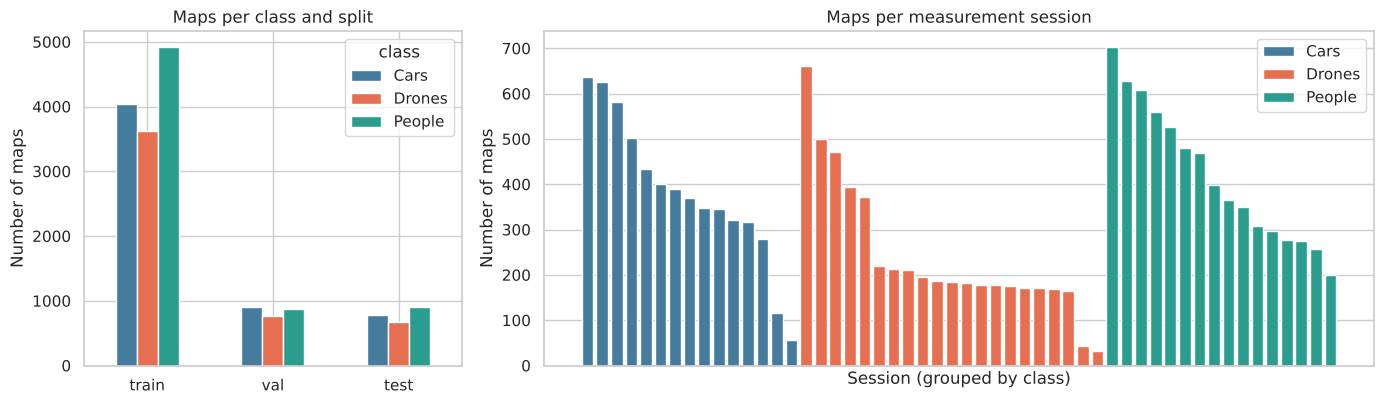

class  Cars  Drones  People
split                      
train  4035    3623    4921
val     905     766     875
test    780     676     904

Maps per session: min 31  median 319  max 703


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
ct = pd.crosstab(pd.Categorical(split, ["train", "val", "test"]), cls, rownames=["split"], colnames=["class"])
ct.plot.bar(ax=axes[0], color=[PAL[c] for c in ct.columns], rot=0)
axes[0].set(title="Maps per class and split", xlabel="", ylabel="Number of maps")

sess_counts = pd.DataFrame({"class": cls, "session": sessions}).value_counts().reset_index(name="maps")
sess_counts = sess_counts.sort_values(["class", "maps"], ascending=[True, False])
sess_counts["label"] = sess_counts["class"].str[0] + ":" + sess_counts["session"]
axes[1].bar(range(len(sess_counts)), sess_counts["maps"], color=sess_counts["class"].map(PAL))
axes[1].set(title="Maps per measurement session", xlabel="Session (grouped by class)", ylabel="Number of maps", xticks=[])
for c in class_names:
    axes[1].bar(0, 0, color=PAL[c], label=c)
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "dl_02_classes_sessions.png", dpi=200); plt.show()
print(ct)
print("\nMaps per session: min", sess_counts.maps.min(), " median", int(sess_counts.maps.median()), " max", sess_counts.maps.max())

## 2. Mean and variability of the maps per class
Each map is cut around the detected target, so the target is always near range bin 5 and Doppler bin 30 (centre). Averaging all maps of a class shows its typical signature; the standard deviation shows where the maps vary most.

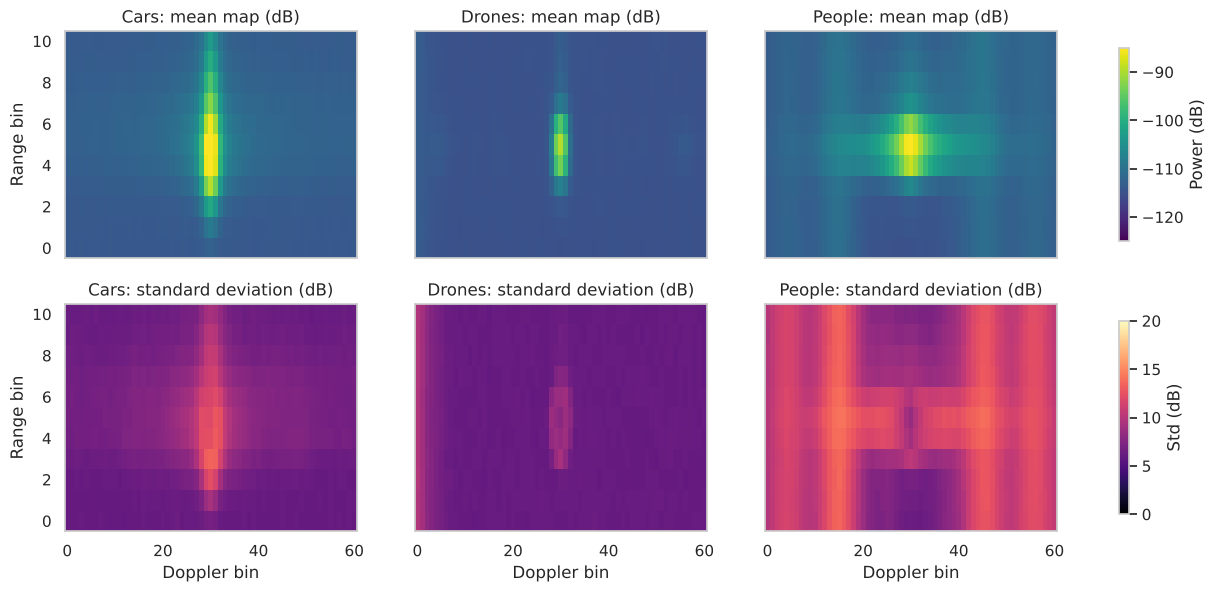

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5), sharex=True, sharey=True)
for j, c in enumerate(class_names):
    m = X[y == j]
    im0 = axes[0, j].imshow(m.mean(0), aspect="auto", origin="lower", cmap="viridis", vmin=-125, vmax=-85)
    im1 = axes[1, j].imshow(m.std(0), aspect="auto", origin="lower", cmap="magma", vmin=0, vmax=20)
    axes[0, j].set_title(f"{c}: mean map (dB)"); axes[1, j].set_title(f"{c}: standard deviation (dB)")
    axes[1, j].set_xlabel("Doppler bin")
axes[0, 0].set_ylabel("Range bin"); axes[1, 0].set_ylabel("Range bin")
for a in axes.ravel(): a.grid(False)
fig.colorbar(im0, ax=axes[0], shrink=0.85, label="Power (dB)")
fig.colorbar(im1, ax=axes[1], shrink=0.85, label="Std (dB)")
plt.savefig(FIG / "dl_03_mean_maps.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Doppler and range profiles
- **Doppler profile**: power averaged over the 11 range bins, as a function of the Doppler bin (radial velocity). A wide profile means energy spread over several velocities (micro-Doppler).
- **Range profile**: power averaged over the central Doppler bins (24–36), as a function of range. A wide profile means a target extended in range.

Lines show the median over all maps of the class; shaded areas the 25–75% range.

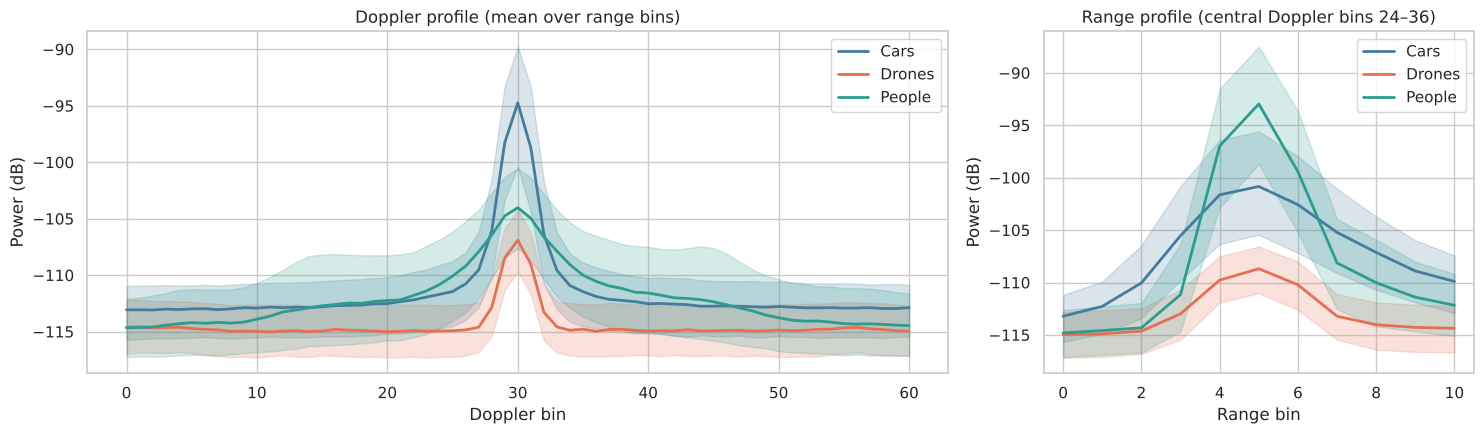

In [4]:
def band(ax, profiles, color, label):
    q25, q50, q75 = np.percentile(profiles, [25, 50, 75], axis=0)
    xs = np.arange(profiles.shape[1])
    ax.plot(xs, q50, color=color, lw=2, label=label)
    ax.fill_between(xs, q25, q75, color=color, alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
for j, c in enumerate(class_names):
    band(axes[0], X[y == j].mean(axis=1), PAL[c], c)
    band(axes[1], X[y == j][:, :, 24:37].mean(axis=2), PAL[c], c)
axes[0].set(title="Doppler profile (mean over range bins)", xlabel="Doppler bin", ylabel="Power (dB)")
axes[1].set(title="Range profile (central Doppler bins 24–36)", xlabel="Range bin", ylabel="Power (dB)")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "dl_04_doppler_range_profiles.png", dpi=200); plt.show()

## 4. Simple physical features of the target signature
Computed for each map, relative to its own noise level (median of the map):
- **Peak power above noise** (dB): strength of the strongest cell in the central region.
- **Doppler width**: number of Doppler bins, on the target's range row, more than 10 dB above the noise (velocity spread, micro-Doppler).
- **Range extent**: number of range bins, on the target's Doppler column, more than 10 dB above the noise (physical size of the target in range).

The central region is range bins 2–8 and Doppler bins 20–40, where the detected target is.

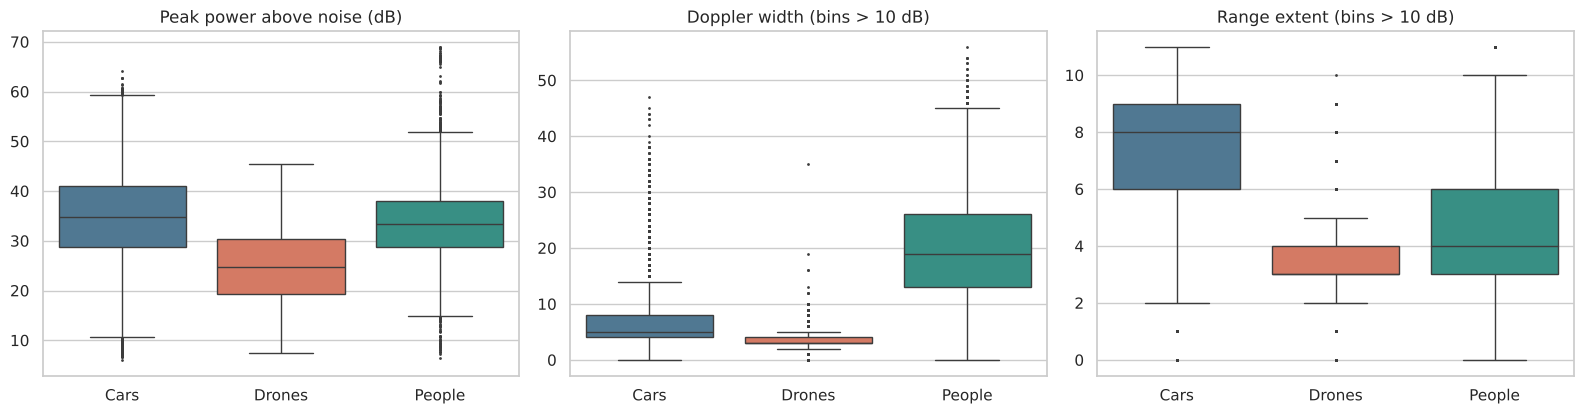

,Peak power above noise (dB),Doppler width (bins > 10 dB),Range extent (bins > 10 dB)
class,,,
Cars,34.799999,5.0,8.0
Drones,24.799999,3.0,3.0
People,33.400002,19.0,4.0


In [5]:
noise = np.median(X.reshape(len(X), -1), axis=1)
center = X[:, 2:9, 20:41]
peak_idx = np.array([np.unravel_index(m.argmax(), m.shape) for m in center])
r_pk, d_pk = peak_idx[:, 0] + 2, peak_idx[:, 1] + 20
rel = X - noise[:, None, None]

feat = pd.DataFrame({
    "class": cls,
    "Peak power above noise (dB)": center.reshape(len(X), -1).max(1) - noise,
    "Doppler width (bins > 10 dB)": (rel[np.arange(len(X)), r_pk, :] > 10).sum(1),
    "Range extent (bins > 10 dB)": (rel[np.arange(len(X)), :, d_pk] > 10).sum(1),
})
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col in zip(axes, feat.columns[1:]):
    sns.boxplot(data=feat, x="class", y=col, hue="class", palette=PAL, order=class_names, legend=False, ax=ax, fliersize=1)
    ax.set(title=col, xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "dl_05_signature_features.png", dpi=200); plt.show()
feat.groupby("class").median().round(1)

## 5. Artefact check: vertical stripes
Many maps show a **strong vertical stripe**: high power at one Doppler bin across **all** 11 range bins, away from the target. A real target occupies a few range bins; a line across all of them at a single velocity looks more like interference or another strong reflector outside the analysed window.

A map is flagged when, at some Doppler bin outside the central region (bins 24–36), **every** range bin is more than 10 dB above the map's noise level.

**Why it matters:** if stripes appear mainly in one class, a network can learn "stripe ⇒ this class" (a *shortcut*) instead of the target signature, and would fail on new data without the artefact.

Maps with a vertical stripe (%):
class
Cars       1.2
Drones     6.1
People    86.3

Trivial rule 'stripe => People':  recall People = 0.86,  false alarms on Cars+Drones = 3.50%


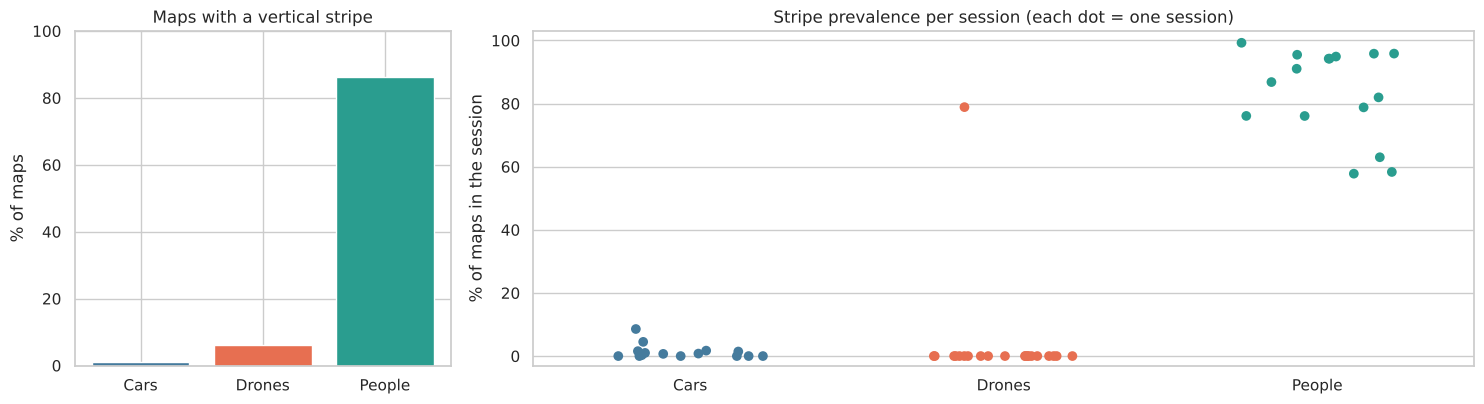

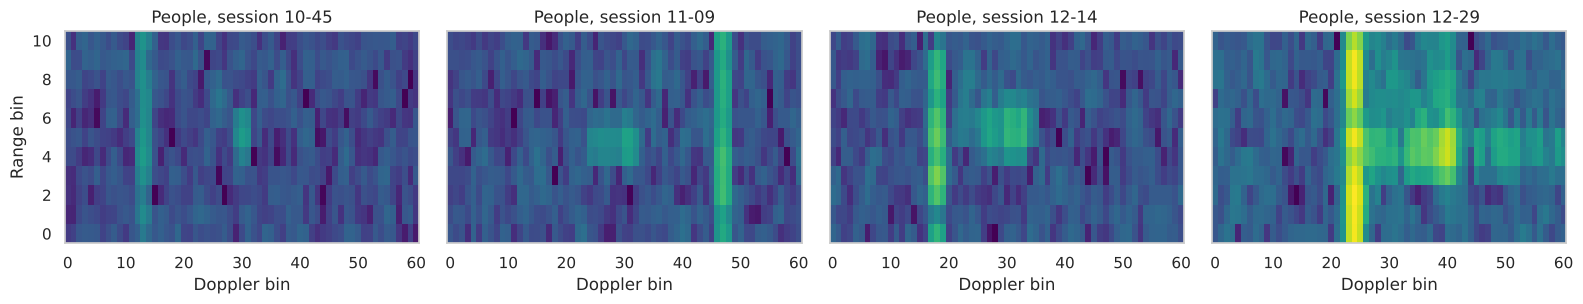

In [6]:
outside = np.r_[0:24, 37:61]
col_min_rel = (X.min(axis=1) - noise[:, None])[:, outside]
stripe = (col_min_rel > 10).any(axis=1)
feat["stripe"] = stripe

prev_class = feat.groupby("class")["stripe"].mean().mul(100).round(1)
print("Maps with a vertical stripe (%):\n" + prev_class.to_string())

# A trivial rule: 'stripe present' => People
pred_people = stripe.astype(int)
tn, fp, fn, tp = confusion_matrix((y == class_names.index("People")).astype(int), pred_people).ravel()
print(f"\nTrivial rule 'stripe => People':  recall People = {tp/(tp+fn):.2f},  "
      f"false alarms on Cars+Drones = {fp/(fp+tn):.2%}")

sess_prev = (pd.DataFrame({"class": cls, "session": sessions, "stripe": stripe})
             .groupby(["class", "session"])["stripe"].mean().mul(100).reset_index())
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 2.5]})
axes[0].bar(prev_class.index, prev_class.values, color=[PAL[c] for c in prev_class.index])
axes[0].set(title="Maps with a vertical stripe", ylabel="% of maps", ylim=(0, 100))
sns.stripplot(data=sess_prev, x="class", y="stripe", hue="class", palette=PAL, order=class_names,
              size=7, jitter=0.25, legend=False, ax=axes[1])
axes[1].set(title="Stripe prevalence per session (each dot = one session)", xlabel="", ylabel="% of maps in the session", ylim=(-3, 103))
plt.tight_layout(); plt.savefig(FIG / "dl_06_stripe_artefact.png", dpi=200); plt.show()

examples = [k for k in np.flatnonzero(stripe & (y == class_names.index("People")))[::900]][:4]
fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 3.2), sharey=True)
for ax, k in zip(np.atleast_1d(axes), examples):
    ax.imshow(X[k], aspect="auto", origin="lower", cmap="viridis", vmin=-135, vmax=-60)
    ax.set(title=f"People, session {sessions[k]}", xlabel="Doppler bin"); ax.grid(False)
np.atleast_1d(axes)[0].set_ylabel("Range bin")
plt.tight_layout(); plt.savefig(FIG / "dl_06b_stripe_examples.png", dpi=200); plt.show()

## 6. Differences between sessions
Each session is one recording (one target, one moment, one place). If sessions of the same class look very different, a model must generalise across conditions — which is exactly what the session-based split tests.

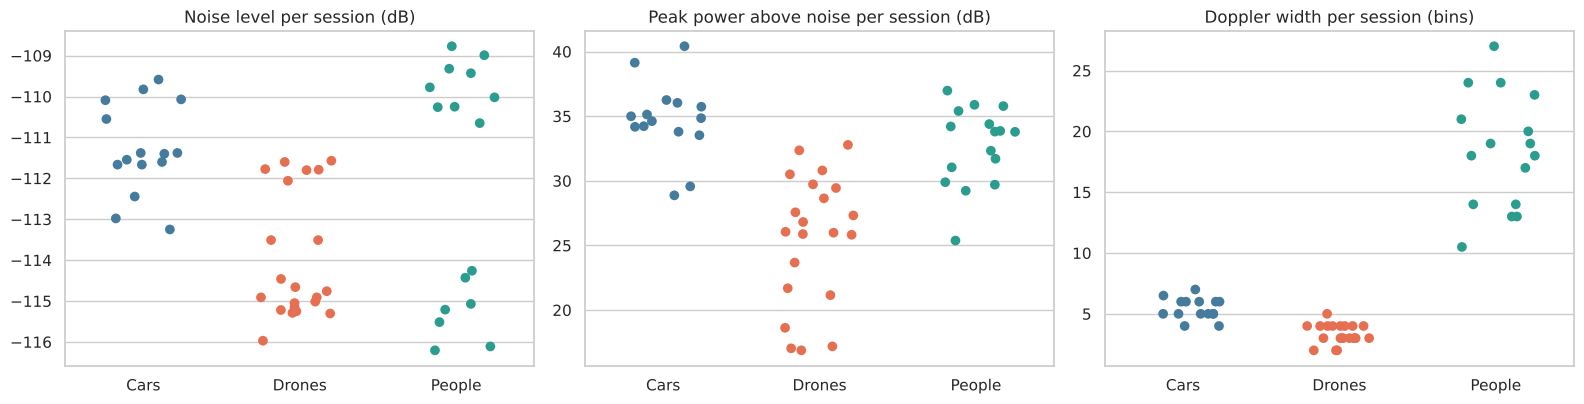

In [7]:
sess_stats = (feat.assign(session=sessions, noise=noise)
              .groupby(["class", "session"])
              .agg(noise=("noise", "median"), peak=("Peak power above noise (dB)", "median"),
                   width=("Doppler width (bins > 10 dB)", "median"))
              .reset_index())
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col, title in zip(axes, ["noise", "peak", "width"],
                          ["Noise level per session (dB)", "Peak power above noise per session (dB)", "Doppler width per session (bins)"]):
    sns.stripplot(data=sess_stats, x="class", y=col, hue="class", palette=PAL, order=class_names,
                  size=7, jitter=0.25, legend=False, ax=ax)
    ax.set(title=title, xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "dl_07_session_variability.png", dpi=200); plt.show()

## 7. PCA of the maps
Each map (671 values) is standardised and projected on the two directions of largest variance. Colours are added afterwards: the projection does not use the labels.

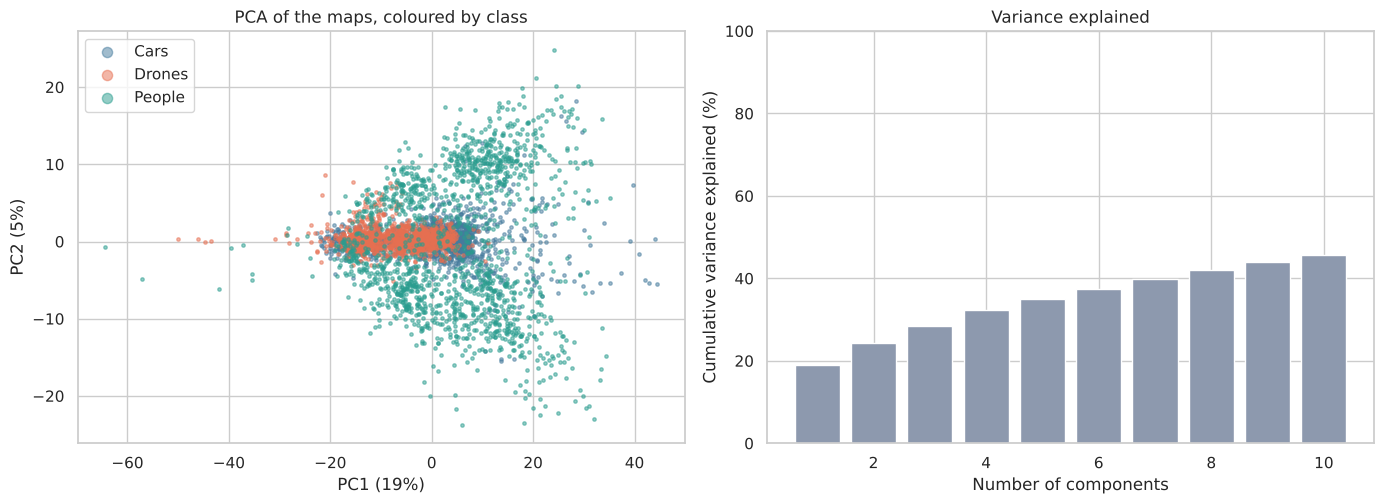

In [8]:
rng = np.random.default_rng(SEED)
sub = rng.choice(len(X), 4000, replace=False)
Z = StandardScaler().fit_transform(X.reshape(len(X), -1))
pca = PCA(n_components=10, random_state=SEED).fit(Z)
P = pca.transform(Z[sub])
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for j, c in enumerate(class_names):
    m = y[sub] == j
    axes[0].scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, color=PAL[c], label=c)
axes[0].set(xlabel=f"PC1 ({ev[0]:.0%})", ylabel=f"PC2 ({ev[1]:.0%})", title="PCA of the maps, coloured by class")
axes[0].legend(markerscale=3)
axes[1].bar(range(1, 11), np.cumsum(ev) * 100, color="#8d99ae")
axes[1].set(xlabel="Number of components", ylabel="Cumulative variance explained (%)", title="Variance explained", ylim=(0, 100))
plt.tight_layout(); plt.savefig(FIG / "dl_08_pca.png", dpi=200); plt.show()

In [9]:
feat.assign(session=sessions, split=split).to_csv(RES / "eda_map_features.csv", index=False)
print("Saved", RES / "eda_map_features.csv")

Saved ../results/eda_map_features.csv


## 8. Conclusions
*(to be written in the report from the outputs above)*